In [34]:
!pip install matplotlib

In [35]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import requests

# Fetch the data.
df = pd.read_csv("https://ourworldindata.org/grapher/children-born-per-woman.csv?v=1&csvType=full&useColumnShortNames=true", storage_options = {'User-Agent': 'Our World In Data data fetch/1.0'})

# Fetch the metadata
metadata = requests.get("https://ourworldindata.org/grapher/children-born-per-woman.metadata.json?v=1&csvType=full&useColumnShortNames=true").json()

In [36]:
df.head()

,entity,code,year,fertility_rate_hist
0,Afghanistan,AFG,1950,7.248
1,Afghanistan,AFG,1951,7.260
2,Afghanistan,AFG,1952,7.260
3,Afghanistan,AFG,1953,7.266
4,Afghanistan,AFG,1954,7.254


In [37]:
df.shape

(19402, 4)

In [38]:
df.columns.tolist()

['entity', 'code', 'year', 'fertility_rate_hist']

In [39]:
df.dtypes

entity                     str
code                       str
year                     int64
fertility_rate_hist    float64
dtype: object

In [40]:
mexico = df[df['entity'] == 'Mexico']
japan = df[df['entity'] == 'Japan']

In [41]:
mexico.shape


(74, 4)

In [42]:
japan.shape

(77, 4)

In [43]:
year_mexico = mexico['year'].to_numpy()
rate_mexico = mexico['fertility_rate_hist'].to_numpy()

year_japan = japan['year'].to_numpy()
rate_japan = japan['fertility_rate_hist'].to_numpy()

In [44]:
promedio_mexico = np.mean(rate_mexico)


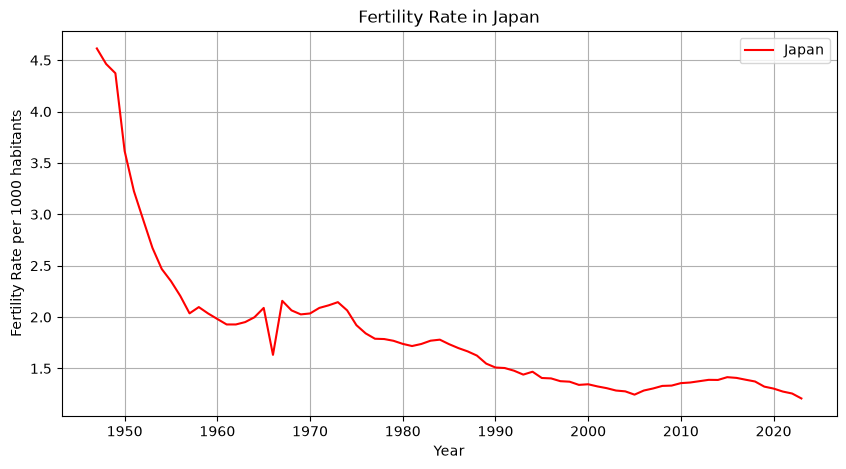

In [45]:
plt.figure(figsize=(10, 5))
plt.plot(
    year_japan, rate_japan, label='Japan', color='red'
)

plt.title('Fertility Rate in Japan')
plt.xlabel('Year')
plt.ylabel('Fertility Rate per 1000 habitants')
plt.grid()
plt.legend()

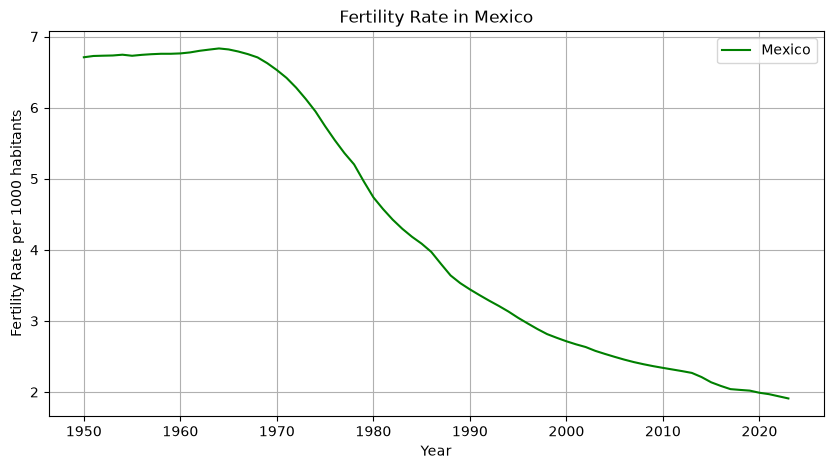

In [46]:
plt.figure(figsize=(10, 5))
plt.plot(
    year_mexico, rate_mexico, label='Mexico', color='green'
)

plt.title('Fertility Rate in Mexico')
plt.xlabel('Year')
plt.ylabel('Fertility Rate per 1000 habitants')
plt.grid()
plt.legend()

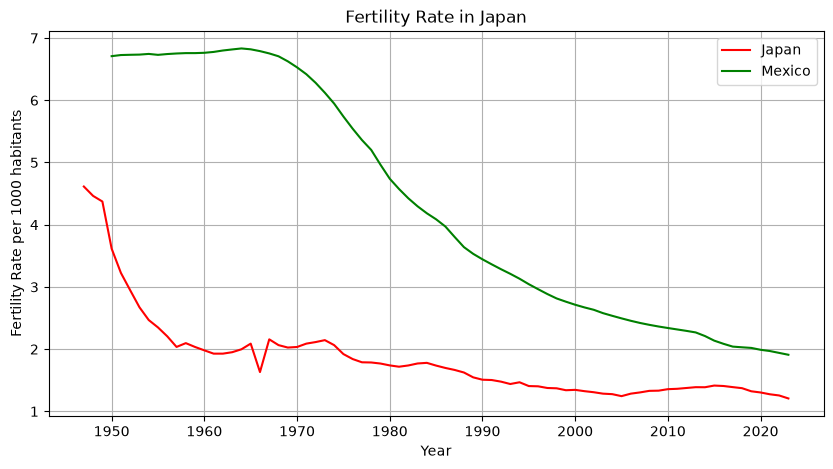

In [47]:
plt.figure(figsize=(10, 5))
plt.plot(
    year_japan, rate_japan, label='Japan', color='red'
)

plt.plot(
    year_mexico, rate_mexico, label='Mexico', color='green'
)

plt.title('Fertility Rate in Japan')
plt.xlabel('Year')
plt.ylabel('Fertility Rate per 1000 habitants')
plt.grid()
plt.legend()



In [48]:
mexico.head(5)

,entity,code,year,fertility_rate_hist
11125,Mexico,MEX,1950,6.709
11126,Mexico,MEX,1951,6.727
11127,Mexico,MEX,1952,6.731
11128,Mexico,MEX,1953,6.734
11129,Mexico,MEX,1954,6.745


In [49]:
japan.head(5)

,entity,code,year,fertility_rate_hist
8384,Japan,JPN,1947,4.614
8385,Japan,JPN,1948,4.463
8386,Japan,JPN,1949,4.373
8387,Japan,JPN,1950,3.615
8388,Japan,JPN,1951,3.225


In [51]:
year_mexico.shape

(74,)

In [52]:
year_japan.shape

(77,)

In [53]:
mascara_coincidencia_year = year_japan >= year_mexico.min()
mascara_coincidencia_year

array([False, False, False,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True,  True,  True,  True,  True,
        True,  True,  True,  True,  True])

In [54]:
year_japan2 = rate_japan[mascara_coincidencia_year]


In [55]:
rate_japan2 = rate_japan[mascara_coincidencia_year]
rate_japan2.shape

(74,)

In [57]:
len(rate_japan2)

74

In [58]:
diferencia_jp_mx = rate_japan2 - rate_mexico

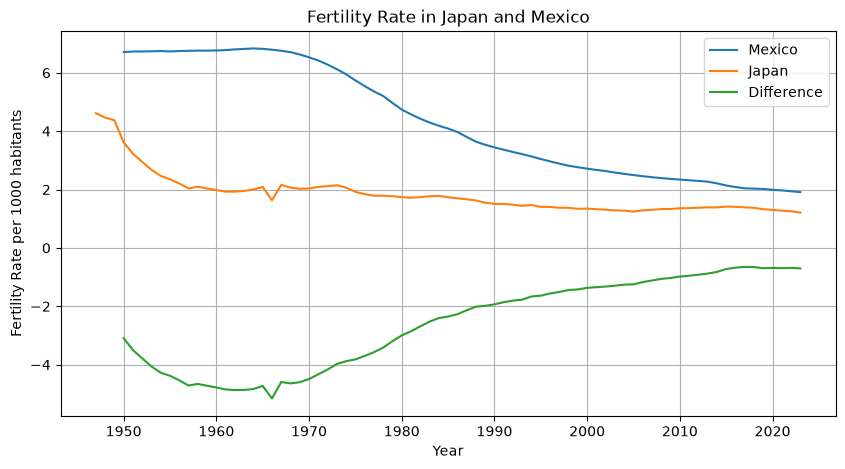

In [60]:
plt.figure(figsize=(10, 5))

plt.plot(
    year_mexico,
    rate_mexico,
    label='Mexico',
)

plt.plot(
    year_japan,
    rate_japan,
    label='Japan',
)

plt.plot(
    year_mexico,
    diferencia_jp_mx,
    label='Difference',
)

plt.title('Fertility Rate in Japan and Mexico')
plt.xlabel('Year')
plt.ylabel('Fertility Rate per 1000 habitants')
plt.grid()
plt.legend()


In [61]:
common_years = np.intersect1d(year_mexico, year_japan)


In [62]:
len(common_years)

74

In [63]:
type(common_years)

numpy.ndarray

In [64]:
mexico_common_years = mexico[mexico['year'].isin(common_years)]
japan_common_years = japan[japan['year'].isin(common_years)]

In [65]:
mexico_rate_common_years = mexico_common_years['fertility_rate_hist'].isin(common_years)
japan_rate_common_years = japan_common_years['fertility_rate_hist'].isin(common_years)

In [66]:
mex_common_years = mexico_common_years['year'].to_numpy()
jap_common_years = japan_common_years['year'].to_numpy()

mex_rate_common_years = mexico_common_years['fertility_rate_hist'].to_numpy()
jap_rate_common_years = japan_common_years['fertility_rate_hist'].to_numpy()


In [67]:
print(year_japan[30])

1977


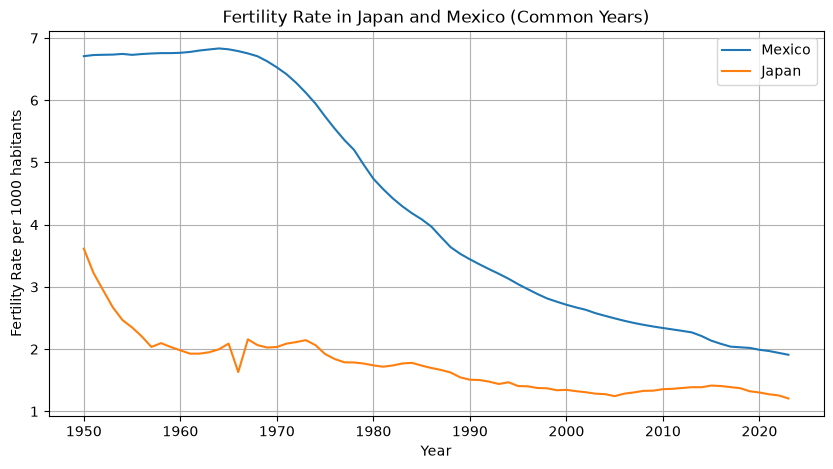

In [68]:
plt.figure(figsize=(10, 5))

plt.plot(
    mex_common_years,
    mex_rate_common_years,
    label='Mexico',
)
plt.plot(
    jap_common_years,
    jap_rate_common_years,
    label='Japan',
)
plt.title('Fertility Rate in Japan and Mexico (Common Years)')
plt.xlabel('Year')
plt.ylabel('Fertility Rate per 1000 habitants')
plt.grid()
plt.legend()

In [69]:
comparison_mex_jap = pd.merge(
    mexico[["year", "fertility_rate_hist"]],
    japan[["year", "fertility_rate_hist"]],
    on="year",
    suffixes=("_mex", "_jap")
    )

In [70]:
comparison_mex_jap.head(3)

,year,fertility_rate_hist_mex,fertility_rate_hist_jap
0,1950,6.709,3.615
1,1951,6.727,3.225
2,1952,6.731,2.947


In [71]:
comparison_mex_jap["diferencia"] = (
    comparison_mex_jap["fertility_rate_hist_jap"] - comparison_mex_jap["fertility_rate_hist_mex"]
)

In [72]:
comparison_mex_jap.head(3)

,year,fertility_rate_hist_mex,fertility_rate_hist_jap,diferencia
0,1950,6.709,3.615,-3.094
1,1951,6.727,3.225,-3.502
2,1952,6.731,2.947,-3.784


<Figure size 1000x500 with 0 Axes>

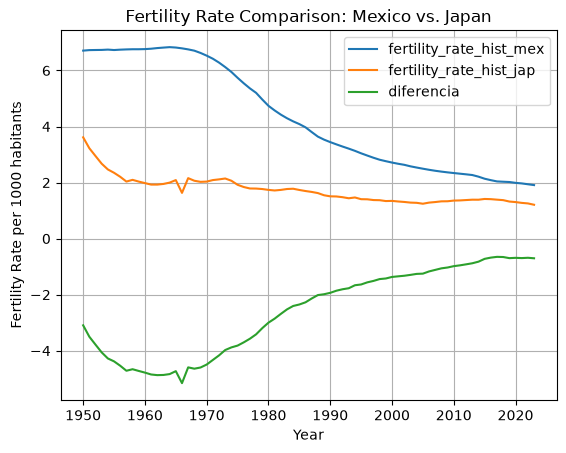

In [73]:
plt.figure(figsize=(10, 5))

comparison_mex_jap.plot(
    x = "year",
    y = ["fertility_rate_hist_mex", "fertility_rate_hist_jap", "diferencia"],
    kind = "line"
)

plt.title("Fertility Rate Comparison: Mexico vs. Japan")
plt.xlabel("Year")
plt.ylabel("Fertility Rate per 1000 habitants")
plt.grid()
plt.legend()